# 大模型微调 08：BERT + PET 小样本文本分类

本篇整理 `08-笔记`、`08-课件`、`08-代码` 和附属资料，完成一个电商用户评论分类项目。方法是使用 BERT 的 Masked Language Model 能力，通过人工硬模板和 Verbalizer 把分类任务改写成完形填空，从而在少量标注数据上完成分类。


## 一、项目背景与 PET 思想

电商评论包含用户对商品、物流和服务的隐式偏好，可用于推荐、质量分析和服务改进。传统 Text-CNN、Text-RNN 或 BERT 全量 Fine-Tuning 通常需要较多标注数据，数据少时容易过拟合。

PET（Pattern-Exploiting Training）的核心是：人工定义 Pattern，把分类任务改写成与 MLM 一致的完形填空，再训练 MLM 任务参数。

示例：

```text
原文：这家店真不错，值得推荐。
模板：[MASK]满意。
标签词：不 → 差评， 很 → 好评
```

PET 的优点是少量样本也能利用预训练知识，缺点是人工模板稳定性差，模板不同可能带来明显的准确率差异。


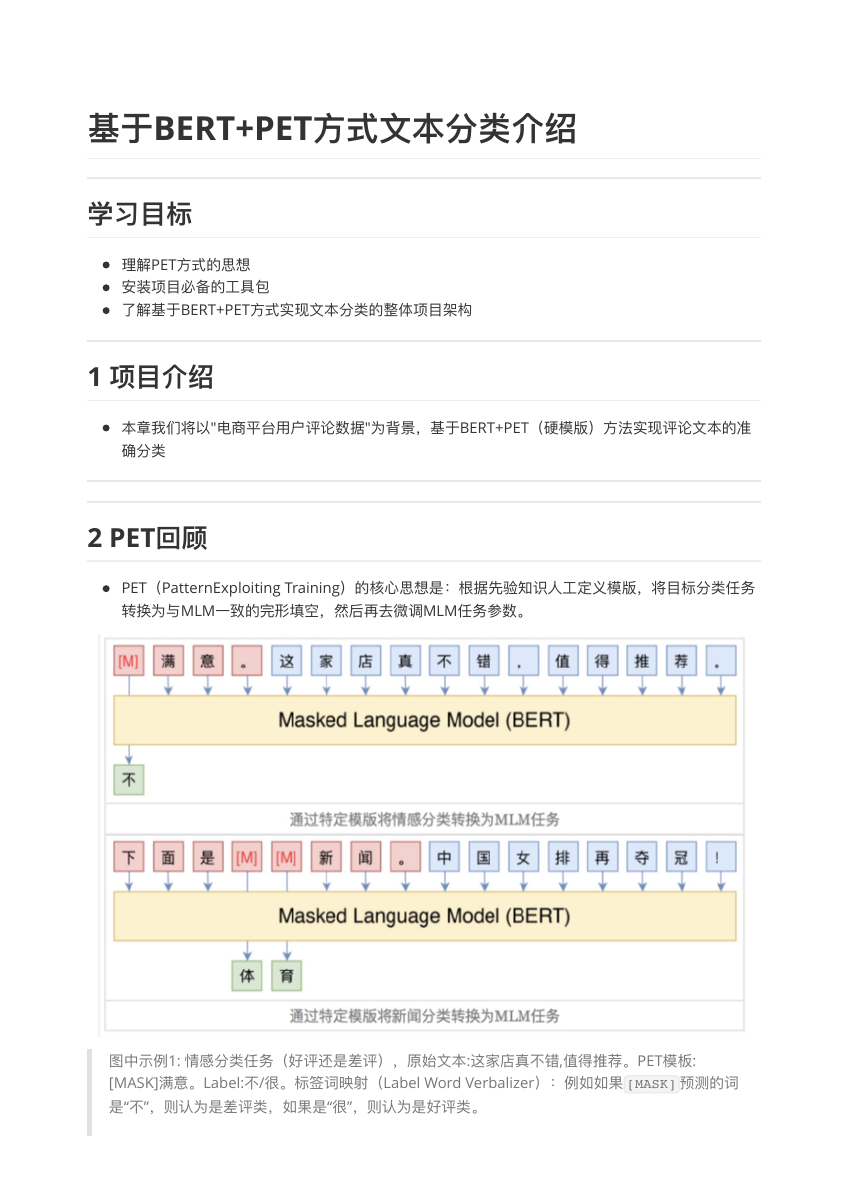

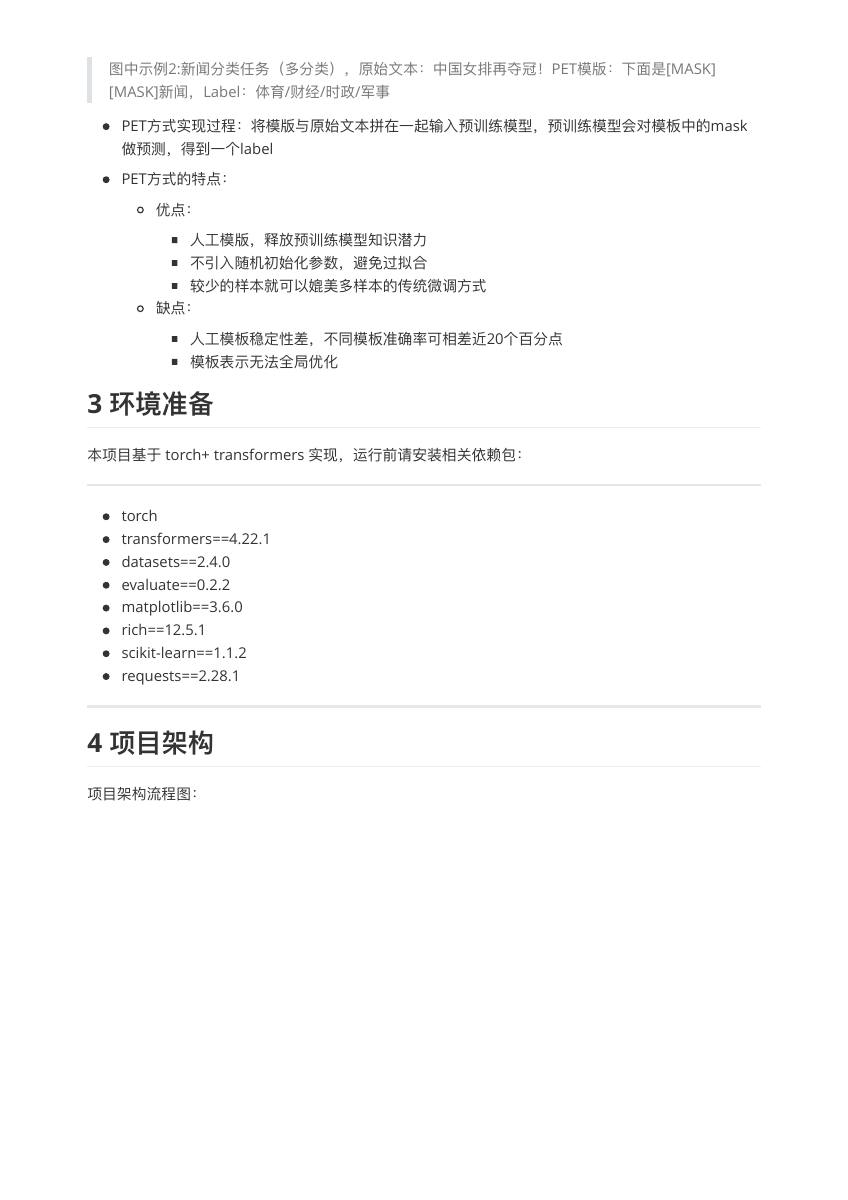

## 二、数据集与配置

`08-代码/data` 中的文件：

| 文件 | 作用 |
| --- | --- |
| `train.txt` | 训练样本，每行 `label\t评论文本`，资料中 63 条 |
| `dev.txt` | 验证样本，资料中约 590 条 |
| `prompt.txt` | 人工硬模板 |
| `verbalizer.txt` | 真实标签到预测词的映射 |

当前模板是：`这是一条{MASK}评论：{textA}。`。`{MASK}` 表示 `[MASK]` 位置，`{textA}` 表示原始评论。Verbalizer 目前包含电脑、水果、平板、衣服、酒店、洗浴、书籍、蒙牛、手机、电器等类别；一对多映射可以写成 `水果\t苹果,香蕉,橘子`。

项目依赖以 `torch`、`transformers==4.22.1`、`datasets==2.4.0`、`evaluate==0.2.2`、`scikit-learn==1.1.2` 等为主。


## 三、HardTemplate：模板到模型输入

`HardTemplate` 解析 `这是一条{MASK}评论：{textA}。`，得到普通字符和自定义字段列表。调用时完成：

1. 把 `MASK` 替换为指定数量的 `[MASK]`；
2. 把 `textA` 替换为评论；
3. 调用 tokenizer，完成截断和 padding；
4. 找到 `[MASK]` 的 token 位置；
5. 返回 `input_ids`、`token_type_ids`、`attention_mask`、`mask_position`。


```python
# -*- coding:utf-8 -*-
from rich import print
from transformers import AutoTokenizer
import numpy as np
from pet_config import *

class HardTemplate(object):
    """
    硬模板，人工定义句子和[MASK]之间的位置关系。
    """

    def __init__(self, prompt: str):
        """
        Args:
            prompt (str): prompt格式定义字符串, e.g. -> "这是一条{MASK}评论：{textA}。"
        """
        self.prompt = prompt
        self.inputs_list = []                       # 根据文字prompt拆分为各part的列表
        self.custom_tokens = set(['MASK'])          # 从prompt中解析出的自定义token集合
        # {'MASK'}
        self.prompt_analysis()                         # 解析prompt模板


    def prompt_analysis(self):
        """
        将prompt文字模板拆解为可映射的数据结构。

        Examples:
            prompt -> "这是一条{MASK}评论：{textA}。"
            inputs_list -> ['这', '是', '一', '条', 'MASK', '评', '论', '：', 'textA', '。']
            custom_tokens -> {'textA', 'MASK'}
        """
        # print(f'prompt-->{self.prompt}')
        idx = 0
        while idx < len(self.prompt):
            str_part = ''
            if self.prompt[idx] not in ['{', '}']:
                self.inputs_list.append(self.prompt[idx])
            if self.prompt[idx] == '{':                  # 进入自定义字段
                idx += 1
                while self.prompt[idx] != '}':
                    str_part += self.prompt[idx]             # 拼接该自定义字段的值
                    idx += 1
            elif self.prompt[idx] == '}':
                raise ValueError("Unmatched bracket '}', check your prompt.")
            if str_part:
                self.inputs_list.append(str_part)
                self.custom_tokens.add(str_part)             # 将所有自定义字段存储，后续会检测输入信息是否完整
            idx += 1


    def __call__(self,
                 inputs_dict: dict,
                 tokenizer,
                 mask_length,
                 max_seq_len=512):
        """
        输入一个样本，转换为符合模板的格式。

        Args:
            inputs_dict (dict): prompt中的参数字典, e.g. -> {
                                                            "textA": "这个手机也太卡了", 
                                                            "MASK": "[MASK]"
                                                        }
            tokenizer: 用于encoding文本
            mask_length (int): MASK token 的长度

        Returns:
            dict -> {
                'text': '[CLS]这是一条[MASK]评论：这个手机也太卡了。[SEP]',
                'input_ids': [1, 47, 10, 7, 304, 3, 480, 279, 74, 47, 27, 247, 98, 105, 512, 777, 15, 12043, 2],
                'token_type_ids': [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0], 
                'attention_mask': [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1],
                'mask_position': [0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]
            }
        """
        # 定义输出格式
        outputs = {
            'text': '', 
            'input_ids': [],
            'token_type_ids': [],
            'attention_mask': [],
            'mask_position': []
        }

        str_formated = ''
        for value in self.inputs_list:
            if value in self.custom_tokens:
                if value == 'MASK':
                    str_formated += inputs_dict[value] * mask_length
                else:
                    str_formated += inputs_dict[value]
            else:
                str_formated += value
        # print(f'str_formated-->{str_formated}')

        encoded = tokenizer(text=str_formated,
                            truncation=True,
                            max_length=max_seq_len,
                            padding='max_length')
        # print('*'*80)
        # print(f'encoded--->{encoded}')
        outputs['input_ids'] = encoded['input_ids']
        outputs['token_type_ids'] = encoded['token_type_ids']
        outputs['attention_mask'] = encoded['attention_mask']

        # print(tokenizer.convert_ids_to_tokens(encoded['input_ids']))
        outputs['text'] = ''.join(tokenizer.convert_ids_to_tokens(encoded['input_ids']))
        # print(f'outputs-->{outputs}')
        # print('*' * 80)
        # print(tokenizer.convert_tokens_to_ids(['[MASK]']))
        mask_token_id = tokenizer.convert_tokens_to_ids(['[MASK]'])[0]
        # print(f'mask_token_id-->{mask_token_id}')
        # print('*' * 80)
        # print(np.array(outputs['input_ids']) == mask_token_id)
        # print('*'*80)
        # print(np.where(np.array(outputs['input_ids']) == mask_token_id))
        mask_position = np.where(np.array(outputs['input_ids']) == mask_token_id)[0].tolist()
        # print(f'mask_position--》{mask_position}')
        outputs['mask_position'] = mask_position
        return outputs


if __name__ == '__main__':
    pc = ProjectConfig()
    tokenizer = AutoTokenizer.from_pretrained(pc.pre_model)
    hard_template = HardTemplate(prompt='这是一条{MASK}评论：{textA}。')
    print(f'inputs_list-->{hard_template.inputs_list}')
    print(f'custom_tokens--》{hard_template.custom_tokens}')
    # print(f"inputs_dict--》{{'textA': '包装不错，苹果挺甜的，个头也大。', 'MASK': '[MASK]'}}")
    tep = hard_template(
                inputs_dict={'textA': '包装不错，苹果挺甜的，个头也大。', 'MASK': '[MASK]'},
                tokenizer=tokenizer,
                max_seq_len=30,
                mask_length=2)
    print(tep)

    # print(tokenizer.convert_ids_to_tokens([3819, 3352, 3819, 3352]))
    # print(tokenizer.convert_tokens_to_ids(['网', '球']))

```

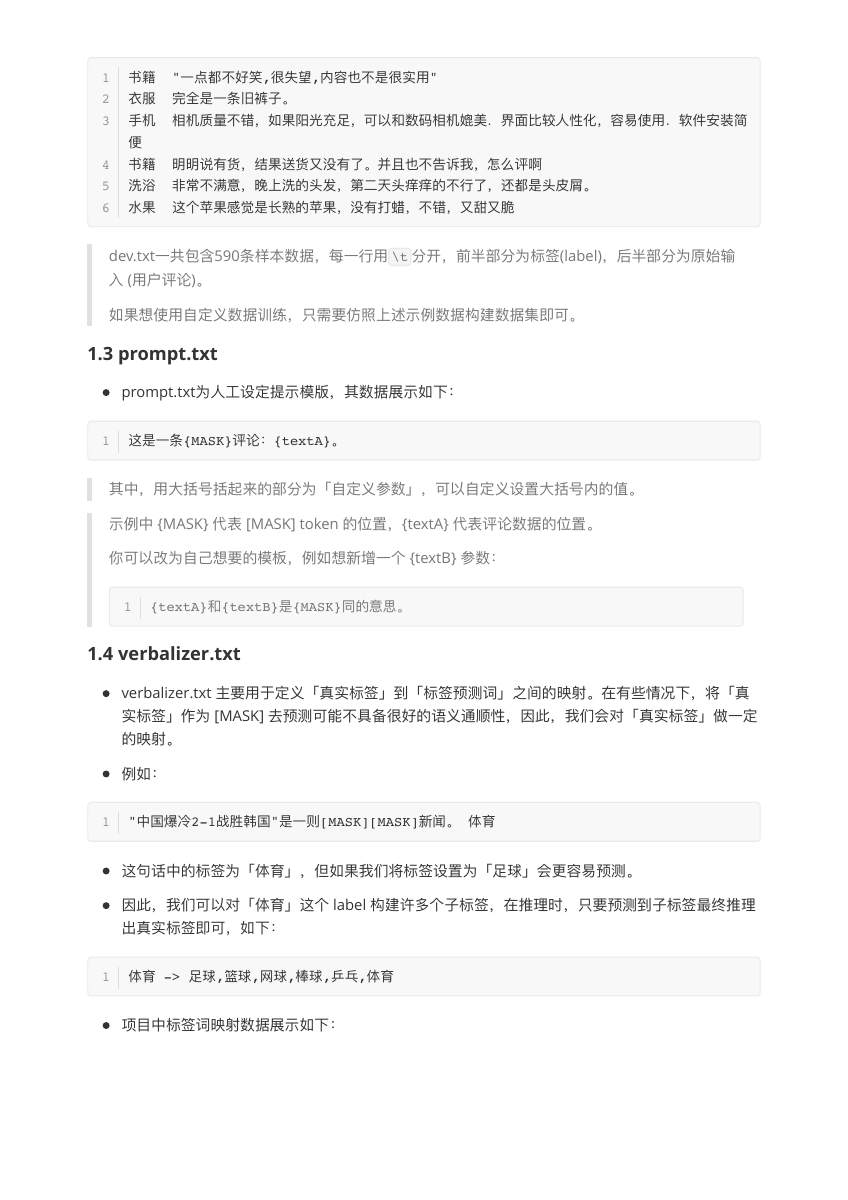

## 四、数据预处理与批次加载

`convert_example()` 在训练模式下拆分 label 和 content，用 HardTemplate 构造输入，再把真实 label tokenize 为 `mask_labels`。输出包括：

- `input_ids`；
- `token_type_ids`；
- `attention_mask`；
- `mask_positions`；
- `mask_labels`。

`data_loader.py` 用 Hugging Face `load_dataset('text')` 读取 train/dev，通过 `default_data_collator` 组成 DataLoader。


```python
# 导入必备工具包
import torch
import numpy as np
from template import *
from rich import print
from datasets import load_dataset
from functools import partial # partial是对函数进行再次封装，便于使用
from pet_config import *


def convert_example(
        examples: dict,
        tokenizer,
        max_seq_len: int,
        max_label_len: int,
        hard_template: HardTemplate,
        train_mode=True,
        return_tensor=False) -> dict:
    print("*"*80)
    """
    将样本数据转换为模型接收的输入数据。

    Args:
        examples (dict): 训练数据样本, e.g. -> {
                                                "text": [
                                                            '手机	这个手机也太卡了。',
                                                            '体育	世界杯为何迟迟不见宣传',
                                                            ...
                                                ]
                                            }
        max_seq_len (int): 句子的最大长度，若没有达到最大长度，则padding为最大长度
        max_label_len (int): 最大label长度，若没有达到最大长度，则padding为最大长度
        hard_template (HardTemplate): 模板类。
        train_mode (bool): 训练阶段 or 推理阶段。
        return_tensor (bool): 是否返回tensor类型，如不是，则返回numpy类型。

    Returns:
        dict (str: np.array) -> tokenized_output = {
                            'input_ids': [[1, 47, 10, 7, 304, 3, 3, 3, 3, 47, 27, 247, 98, 105, 512, 777, 15, 12043, 2], ...],
                            'token_type_ids': [[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0], ...],
                            'attention_mask': [[1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1], ...],
                            'mask_positions': [[5, 6, 7, 8], ...],
                            'mask_labels': [[2372, 3442, 0, 0], [2643, 4434, 2334, 0], ...]
                        }
    """
    tokenized_output = {
        'input_ids': [],
        'token_type_ids': [],
        'attention_mask': [],
        'mask_positions': [],
        'mask_labels': []
    }
    # print(f'examples--》{examples}')
    for i, example in enumerate(examples['text']):
        if train_mode:
            # print(f'example-->{example}')
            label, content = example.strip().split('\t')
            # print(f'label-->{label}')
            # print(f'content-->{content}')
        else:
            content = example.strip()

        inputs_dict = {
            'textA': content,
            'MASK': '[MASK]'
        }
        # print(f'inputs_dict-->{inputs_dict}')

        encoded_inputs = hard_template(
            inputs_dict=inputs_dict,
            tokenizer=tokenizer,
            max_seq_len=max_seq_len,
            mask_length=max_label_len)
        # print(f'encoded_inputs--》{encoded_inputs}')
        # print('*'*80)
        tokenized_output['input_ids'].append(encoded_inputs["input_ids"])
        tokenized_output['token_type_ids'].append(encoded_inputs["token_type_ids"])
        tokenized_output['attention_mask'].append(encoded_inputs["attention_mask"])
        tokenized_output['mask_positions'].append(encoded_inputs["mask_position"])
        # print(f'tokenized_output-->{tokenized_output}')

        if train_mode:
            # print(f'label--》{label}')
            label_encoded = tokenizer(text=[label])  # 将label补到最大长度
            # print(f'label_encoded-->{label_encoded}')

            label_encoded = label_encoded['input_ids'][0][1:-1]
            # print(f'label_encoded-->{label_encoded}')

            label_encoded = label_encoded[:max_label_len]
            # print(f'tokenizer.pad_token_id-->{tokenizer.pad_token_id}')
            label_encoded = label_encoded + [tokenizer.pad_token_id] * (max_label_len - len(label_encoded))

            tokenized_output['mask_labels'].append(label_encoded)
    for k, v in tokenized_output.items():
        if return_tensor:
            tokenized_output[k] = torch.LongTensor(v)
        else:
            tokenized_output[k] = np.array(v)

    return tokenized_output


if __name__ == '__main__':
    pc = ProjectConfig()
    train_dataset = load_dataset('text', data_files=pc.train_path)
    # print(f'train_dataset-->{train_dataset}')
    # print('*'*80)
    # print(train_dataset['train'])
    # print('*'*80)
    # print(train_dataset['train']['text'])
    tokenizer = AutoTokenizer.from_pretrained(pc.pre_model)
    hard_template = HardTemplate(prompt='这是一条{MASK}评论：{textA}')
    examples = {"text": ['手机	这个手机也太卡了。','体育	世界杯为何迟迟不见宣传']}
    #
    # tokenized_output = convert_example(examples=examples,
    #                                     tokenizer=tokenizer,
    #                                     max_seq_len=30,
    #                                     max_label_len=2,
    #                                     hard_template=hard_template,
    #                                     train_mode=True,
    #                                     return_tensor=False)
    #
    # print(f'tokenized_output-->{tokenized_output}')
    convert_func = partial(convert_example,
                           tokenizer=tokenizer,
                           hard_template=hard_template,
                           max_seq_len=30,
                           max_label_len=2,
                           )

    # # # # batched=True相当于将train_dataset看成一个批次的样本直接对数据进行处理，节省时间
    dataset = train_dataset.map(convert_func, batched=True)
    print(f"dataset-->{dataset}")
    print(f"dataset['train']--》{dataset['train']}")
    print("*"*80)
    print(len(dataset['train']))
    print("*" * 80)
    print(dataset["train"][0])
    # for value in dataset['train']:
    #     print(value)
    #     print(len(value['input_ids']))
    #     print(type(value['input_ids']))
    #     break

```

```python
# coding:utf-8
from torch.utils.data import DataLoader
from transformers import default_data_collator
from data_preprocess import *
from pet_config import *

pc = ProjectConfig() # 实例化项目配置文件
tokenizer = AutoTokenizer.from_pretrained(pc.pre_model)

def get_data():
    prompt = open(pc.prompt_file, 'r', encoding='utf8').readlines()[0].strip()  # prompt定义
    # print(f'prompt--》{prompt}')
    hard_template = HardTemplate(prompt=prompt)  # 模板转换器定义
    dataset = load_dataset('text', data_files={'train': pc.train_path,
                                               'dev': pc.dev_path})
    # print(f'dataset-->{dataset}')
    # print(f'Prompt is -> {prompt}')
    new_func = partial(convert_example,
                       tokenizer=tokenizer,
                       hard_template=hard_template,
                       max_seq_len=pc.max_seq_len,
                       max_label_len=pc.max_label_len)
    # print("*"*80)
    dataset = dataset.map(new_func, batched=True)
    # print(f'dataset改变之后的-->{dataset}')
    train_dataset = dataset["train"]
    # print(f'train_dataset[0]--》{train_dataset[0]}')
    dev_dataset = dataset["dev"]
    # print(f'dev_dataset--》{dev_dataset}')
    # print('dev_dataset', dev_dataset[0])
    # print('*'*80)
    # default_data_collator作用，转换为tensor数据类型
    train_dataloader = DataLoader(train_dataset,
                                  shuffle=True,
                                  collate_fn=default_data_collator,
                                  batch_size=pc.batch_size)
    dev_dataloader = DataLoader(dev_dataset,
                                collate_fn=default_data_collator,
                                batch_size=pc.batch_size)
    return train_dataloader, dev_dataloader


if __name__ == '__main__':
    train_dataloader, dev_dataloader = get_data()
    print(len(train_dataloader))
    print(len(dev_dataloader))
    for i, value in enumerate(train_dataloader):
        print(i)
        print(value)
        print(value['input_ids'].dtype)
        break

```

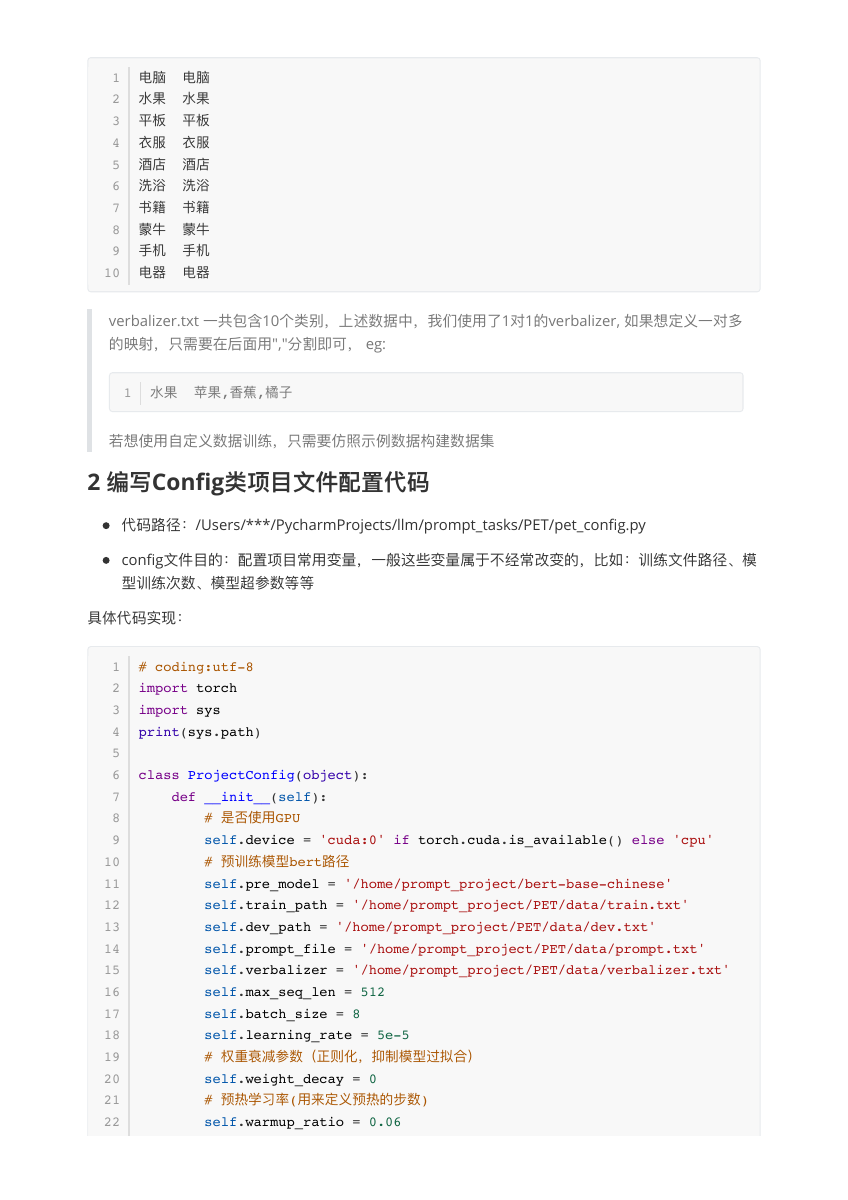

## 五、模型训练与指标

模型直接加载 `AutoModelForMaskedLM`。训练循环加载 tokenizer、模型和 Verbalizer，在 mask 位置提取 logits，把真实标签映射到子标签 token，再计算 MLM loss。优化器使用 AdamW，学习率采用线性调度和 warmup。

评估使用 Accuracy、Precision、Recall、F1 和每类指标。资料示例中，约 60 条训练样本在接近 600 条验证样本上得到 precision 约 0.78、recall 约 0.77、F1 约 0.76；部分类别表现较弱，说明小样本和类别覆盖仍然是主要限制。


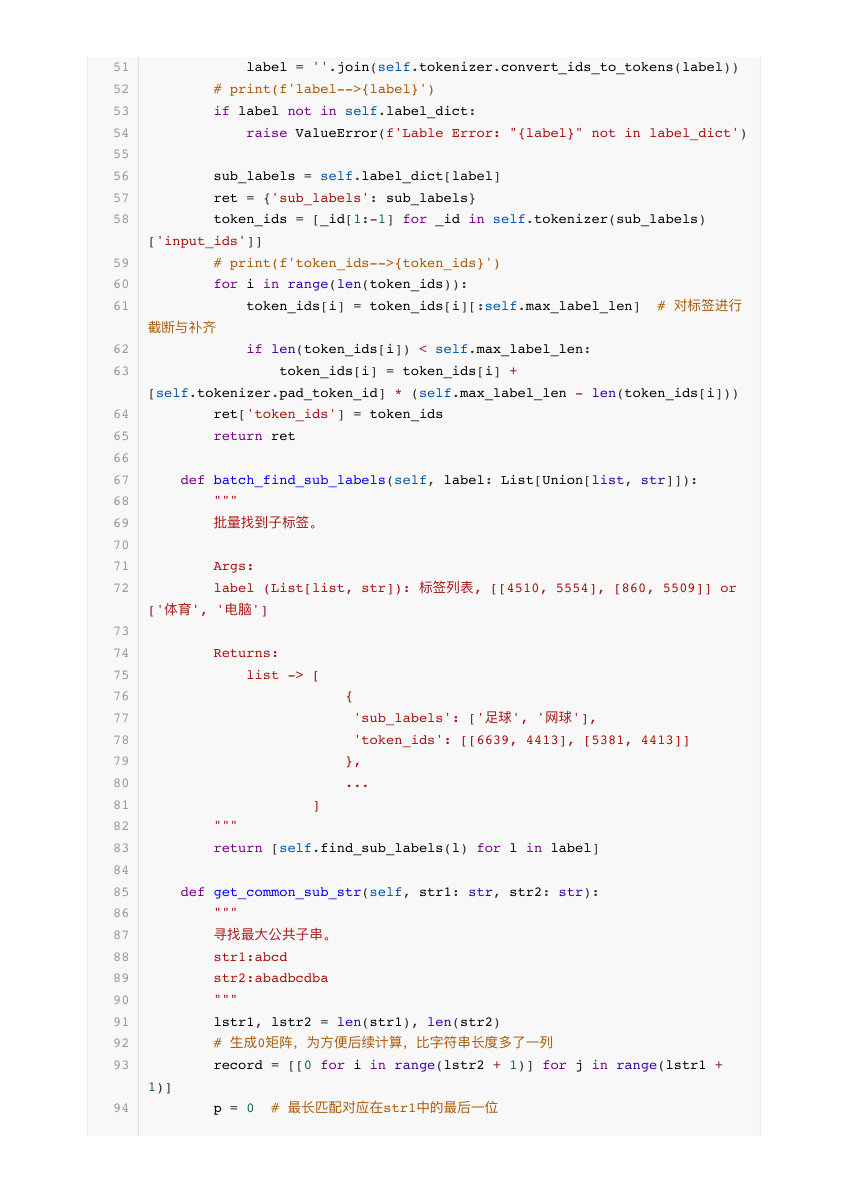

模型工具类通常分为三部分：

- `verbalizer.py`：主标签与子标签映射；
- `common_utils.py`：mask 位置 logits 转 token ID，以及 MLM loss；
- `metirc_utils.py`：累计预测和真实标签，计算 Accuracy、Precision、Recall、F1 和混淆矩阵。

验证 F1 提升时保存 `model_best`，推理阶段必须同时加载同一 checkpoint 的模型、tokenizer 和 Verbalizer。


## 六、推理流程

1. 加载 `checkpoints/model_best`；
2. 读取 Prompt 和 Verbalizer；
3. 将原始评论包装成 `{'text': contents}`；
4. 复用 `convert_example(train_mode=False)`；
5. 从 mask logits 得到预测 token；
6. 用 Verbalizer 还原主类别。

示例评论可能被归类为酒店、平板、水果等类别。推理时的模板、`max_label_len` 和训练阶段必须一致。


## 七、易错点与验证顺序

- 模板字段名必须和 `inputs_dict` 一致；
- `[MASK]` 数量要覆盖最长 label；
- 训练文件必须用 tab 分隔标签和文本；
- 多标签 Verbalizer 要在指标计算前还原主标签；
- tokenizer、BERT 模型和 Transformers 版本要兼容；
- 小样本指标波动较大，应同时查看每类 F1 和混淆矩阵；
- 增加样本时要尽量保持类别均衡，并覆盖同一类别的不同表达方式。


## 八、本章总结

- PET 用硬模板把分类变成 MLM 完形填空，借助 BERT 预训练知识完成少样本分类。
- HardTemplate 负责模板解析、tokenize、padding 和 mask 位置定位。
- Verbalizer 负责真实标签与预测词映射，一对多映射可提升语义自然度。
- 数据管道由 `convert_example`、Dataset/DataLoader 和 collator 组成。
- 训练只在 `[MASK]` 位置计算 MLM loss，并用 Accuracy、Precision、Recall、F1 评估。
- 预测阶段复用同一模板和 Verbalizer，把 mask 预测结果还原为业务类别。
